In [15]:
import pandas as pd 
import numpy as np 
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,classification_report,confusion_matrix)

import matplotlib.pyplot as plt
import seaborn as sns


# 
pandas: loading and handling datasets.
scikit-learn: building machine learning models.
OneHotEncoder: converting machine categories into numerical form.
StandardScaler: putting numerical features on a comparable scale.
Pipeline: connecting preprocessing and model training safely.
metrics: evaluating predictions.

In [16]:
x_train = pd.read_csv("C:/Projects/smart-industrial-predictive-maintenance/data/processed/x_train.csv")
x_test = pd.read_csv("C:/Projects/smart-industrial-predictive-maintenance/data/processed/x_test.csv")
y_train = pd.read_csv("C:/Projects/smart-industrial-predictive-maintenance/data/processed/y_train.csv").squeeze()
y_test= pd.read_csv("C:/Projects/smart-industrial-predictive-maintenance/data/processed/y_test.csv").squeeze()
print(f"x train shapec:{x_train.shape}")
print(f"x_test shape :{x_test.shape}")
print(f"training target distribution:{y_train.value_counts()}")
print(f"testing targest distribution:{y_test.value_counts()}")
print(f"shape of y train:{y_train.shape}")
print(f'shape of y test:{y_test.shape}')
 

x train shapec:(8000, 7)
x_test shape :(2000, 7)
training target distribution:Machine failure
0    7729
1     271
Name: count, dtype: int64
testing targest distribution:Machine failure
0    1932
1      68
Name: count, dtype: int64
shape of y train:(8000,)
shape of y test:(2000,)


# We use .squeeze() to convert a single column DataFrame into a onedimensional Series. Most Scikit-learn classification algorithms expect the target variable in a one dimensional format, so it helps us provide the correct input shape.

In [17]:
categorical_features = ["Type"]
numerical_features= ["Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature difference"]

preprocessor = ColumnTransformer(transformers=[("categorical",OneHotEncoder(handle_unknown="ignore"),categorical_features),
("numerical",StandardScaler(),numerical_features)])     

In [18]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42),

    "KNN": KNeighborsClassifier(
        n_neighbors=5),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42)
}

In [19]:
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Train model
    pipeline.fit(x_train, y_train)

    # Predict test data
    y_pred = pipeline.predict(x_test)

    # Predict failure probabilities
    y_probability = pipeline.predict_proba(x_test)[:, 1]

    # Evaluate
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_probability),
        "PR-AUC": average_precision_score(y_test, y_probability)
    })

    trained_models[name] = pipeline

    print(f"{name}")
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))

results_df = pd.DataFrame(results)

Logistic Regression
              precision    recall  f1-score   support

           0       0.99      0.83      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.83      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.83      0.88      2000

KNN
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.88      0.32      0.47        68

    accuracy                           0.98      2000
   macro avg       0.93      0.66      0.73      2000
weighted avg       0.97      0.98      0.97      2000

Decision Tree
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.72      0.69      0.71        68

    accuracy                           0.98      2000
   macro avg       0.86      0.84      0.85      2000
weighted avg       0.98      0.98   

In [20]:
results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8255,0.142494,0.823529,0.242950,0.906901,0.381365
1,KNN,0.9755,0.880000,0.323529,0.473118,0.875148,0.519327
2,Decision Tree,0.9805,0.723077,0.691176,0.706767,0.840930,0.510274
3,Random Forest,0.9875,0.841270,0.779412,0.809160,0.971072,0.844610


In [24]:
a=results_df.value_counts()

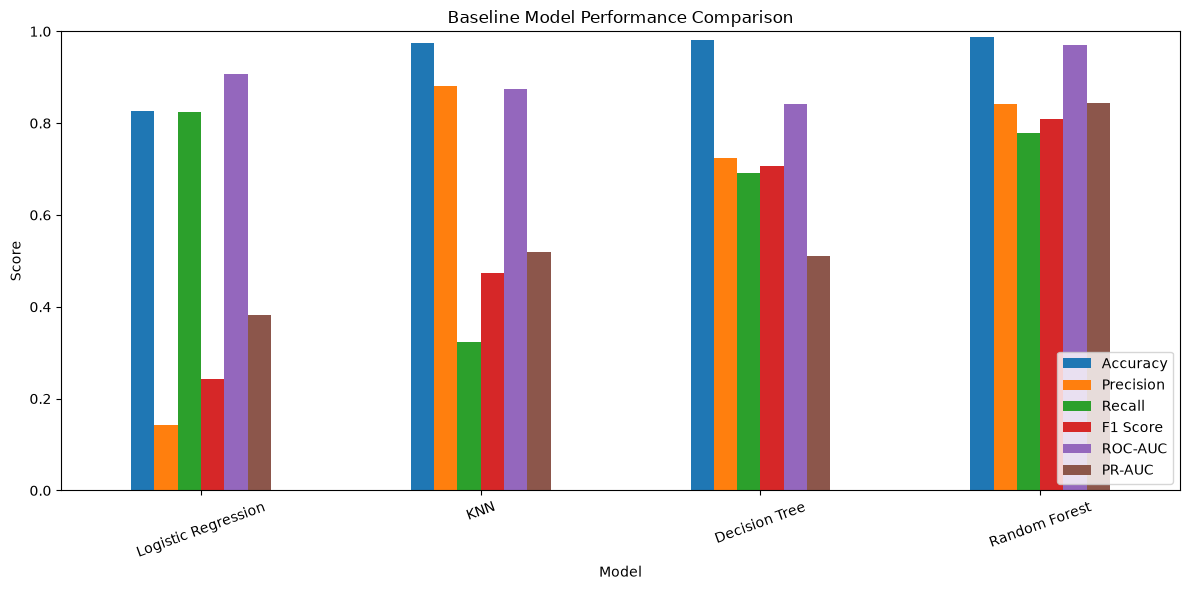

In [28]:

results_df.set_index("Model")[
    ["Accuracy","Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"]
].plot(kind="bar", figsize=(12, 6))
plt.title("Baseline Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()